<a href="https://colab.research.google.com/github/Umair01-code/FlyRank-ML-Intrenship/blob/main/work/notebooks/w05_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Umair01-code/FlyRank-ML-Intrenship/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

Lane: **Refresh / Content Opportunity Scoring.** Everything below uses the March 2026 warehouse slice from my Week 3 contract and Week 4 baseline. Random seed is 42 everywhere.

## 1. Method choice and why

My question for this notebook: **which pages should a content team look at first because they are slipping?**

To turn that into something I can model I need a label I can actually observe, so I build weekly rows from the daily warehouse data. One row is one page (client + content item) at one decision date.

- **Features:** only the 7 days before the decision date, plus the 7 days before that so the model can see momentum.
- **Label:** 1 if the page's clicks in the next 7 days are at least 30% lower than in the previous 7 days, otherwise 0.
- **Eligible pages:** at least 10 clicks in the previous week, and a complete 7-day Search Console history in both the "before" and "after" windows. Without this filter a page going from 1 click to 0 would count as a big drop, and a few missing days would look like a drop too.

I moved from my Week 3 regression label (`future_7d_gsc_clicks`) to this yes/no version on purpose. My lane is about ranking pages for review, and my Week 2 success metric was Precision@50, which needs a yes/no label. It uses the same two click columns, so nothing from the future leaks into the features.

**Why these methods (from this week's menu):**

- The label is observed and yes/no, so I start with **Logistic Regression** because I can read it, then a **depth-3 Decision Tree** I can print, then **Random Forest** and **Gradient Boosting** to see if the extra complexity earns anything.
- I am not using clustering. There is a label, so grouping pages without one does not answer the question.
- **Permutation importance** at the end, to check what the best model really leans on.
- The **Week 4 rule baseline** goes in the same table. It ranks pages with high visibility and weak CTR. It was not built to predict drops, so I do not expect it to do well here. That is a fair thing to find out: is "looks like an opportunity" the same as "is slipping"?

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1


In [3]:
# Warehouse connection. The token comes from Colab Secrets and is never printed.
%pip -q install duckdb

import duckdb
from google.colab import userdata

con = duckdb.connect()
con.execute(f"""
    CREATE OR REPLACE SECRET hf (
        TYPE huggingface,
        TOKEN '{userdata.get("HF_TOKEN")}'
    )
""")
print("Connected to the warehouse.")

Connected to the warehouse.


In [4]:
!pip install pandas duckdb pyarrow

In [6]:
# Settings for the weekly frame. Change them here, nowhere else.
import pandas as pd
DECISION_DATES = ["2026-03-08", "2026-03-15", "2026-03-22", "2026-03-29"]  # weekly, windows do not overlap
MIN_PREV_CLICKS = 10      # page must have at least this many clicks in the previous 7 days
DROP_FRACTION = 0.30      # label = 1 if next-7-day clicks <= (1 - 0.30) * previous-7-day clicks

ROOT = "hf://datasets/FlyRank/internship-warehouse/fact_content_daily_performance"
MONTHS = ["2026-02", "2026-03", "2026-04"]   # Feb for the "week before last", Apr for the outcome of late March
FILES = [f"{ROOT}/month={m}/*.parquet" for m in MONTHS]

first = pd.Timestamp(min(DECISION_DATES)) - pd.Timedelta(days=14)
last = pd.Timestamp(max(DECISION_DATES)) + pd.Timedelta(days=7)
date_list = ", ".join(f"DATE '{d}'" for d in DECISION_DATES)

sql = f"""
WITH d AS (
    SELECT UNNEST([{date_list}]) AS decision_date
),
base AS (
    SELECT
        report_date, client_hash_id, content_hash_id,
        gsc_clicks, gsc_impressions,
        NULLIF(gsc_avg_position, 0) AS pos,
        CASE WHEN ga4_data_available IS TRUE THEN sessions_organic END AS organic,
        CASE WHEN ga4_data_available IS TRUE THEN scroll_events END AS scroll,
        (ga4_data_available IS TRUE) AS ga4_ok
    FROM read_parquet({FILES})
    WHERE gsc_data_available IS TRUE          -- zero-filled rows are not real zeros
      AND report_date BETWEEN DATE '{first.date()}' AND DATE '{last.date()}'
),
agg AS (
    SELECT
        d.decision_date, b.client_hash_id, b.content_hash_id,

        COUNT(*)              FILTER (WHERE b.report_date BETWEEN d.decision_date - 7  AND d.decision_date - 1) AS prev_days,
        SUM(b.gsc_clicks)     FILTER (WHERE b.report_date BETWEEN d.decision_date - 7  AND d.decision_date - 1) AS prev_clicks,
        SUM(b.gsc_impressions) FILTER (WHERE b.report_date BETWEEN d.decision_date - 7 AND d.decision_date - 1) AS prev_impr,
        AVG(b.pos)            FILTER (WHERE b.report_date BETWEEN d.decision_date - 7  AND d.decision_date - 1) AS prev_pos,
        COUNT(*)              FILTER (WHERE b.ga4_ok AND b.report_date BETWEEN d.decision_date - 7 AND d.decision_date - 1) AS prev_ga4_days,
        SUM(b.organic)        FILTER (WHERE b.report_date BETWEEN d.decision_date - 7  AND d.decision_date - 1) AS prev_organic,
        SUM(b.scroll)         FILTER (WHERE b.report_date BETWEEN d.decision_date - 7  AND d.decision_date - 1) AS prev_scroll,

        COUNT(*)              FILTER (WHERE b.report_date BETWEEN d.decision_date - 14 AND d.decision_date - 8) AS prior_days,
        SUM(b.gsc_clicks)     FILTER (WHERE b.report_date BETWEEN d.decision_date - 14 AND d.decision_date - 8) AS prior_clicks,

        COUNT(*)              FILTER (WHERE b.report_date BETWEEN d.decision_date + 1  AND d.decision_date + 7) AS future_days,
        SUM(b.gsc_clicks)     FILTER (WHERE b.report_date BETWEEN d.decision_date + 1  AND d.decision_date + 7) AS future_clicks
    FROM d
    JOIN base b ON b.report_date BETWEEN d.decision_date - 14 AND d.decision_date + 7
    GROUP BY d.decision_date, b.client_hash_id, b.content_hash_id
)
SELECT * FROM agg
WHERE prev_days = 7 AND future_days = 7       -- complete windows only
  AND prev_clicks >= {MIN_PREV_CLICKS}
"""

CACHE = Path("w05_weekly_frame.parquet")   # local cache only, never committed (parquet is gitignored)
if CACHE.exists():
    raw = pd.read_parquet(CACHE)
    print("Loaded cached frame:", CACHE)
else:
    raw = con.sql(sql).df()
    raw.to_parquet(CACHE, index=False)
    print("Queried the warehouse and cached the result.")

print("Rows:", f"{len(raw):,}")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Queried the warehouse and cached the result.
Rows: 16,446
Loaded cached frame: w05_weekly_frame.parquet
Rows: 16,446


In [7]:
frame = raw.copy()
frame["decision_date"] = pd.to_datetime(frame["decision_date"])
for c in ["prev_clicks", "prev_impr", "prior_clicks", "future_clicks", "prev_organic", "prev_scroll"]:
    frame[c] = frame[c].astype(float)

# Features that exist at the decision moment
frame["prev_ctr"] = frame["prev_clicks"] / frame["prev_impr"].replace(0, np.nan)
has_prior = frame["prior_days"] == 7
frame["has_prior"] = has_prior.astype(int)
frame["prior_clicks"] = frame["prior_clicks"].where(has_prior)
frame["clicks_change"] = ((frame["prev_clicks"] - frame["prior_clicks"]) / (frame["prior_clicks"] + 1)).clip(-1, 5)
frame["has_position"] = frame["prev_pos"].notna().astype(int)

# Label: a drop of at least DROP_FRACTION (uses future clicks, so it is never a feature)
frame["y"] = (frame["future_clicks"] <= (1 - DROP_FRACTION) * frame["prev_clicks"]).astype(int)

frame = frame.sort_values(["decision_date", "client_hash_id", "content_hash_id"]).reset_index(drop=True)

FEATURES = ["prev_clicks", "prev_impr", "prev_ctr", "prev_pos", "prior_clicks", "clicks_change",
            "prev_organic", "prev_scroll", "prev_ga4_days", "has_prior", "has_position"]

print("Eligible page-weeks:", f"{len(frame):,}")
print("Clients:", frame["client_hash_id"].nunique(), "| distinct pages:", frame[["client_hash_id", "content_hash_id"]].drop_duplicates().shape[0])
print("Base rate (share of pages that dropped):", round(frame["y"].mean(), 3))
print()
print(frame.groupby("decision_date")["y"].agg(rows="size", base_rate="mean").round(3))
print()
print("Missing values in features:")
print(frame[FEATURES].isna().mean().round(3).to_string())

Eligible page-weeks: 16,446
Clients: 26 | distinct pages: 7627
Base rate (share of pages that dropped): 0.385

               rows  base_rate
decision_date                 
2026-03-08     3729      0.417
2026-03-15     3787      0.422
2026-03-22     3979      0.340
2026-03-29     4951      0.370

Missing values in features:
prev_clicks      0.000
prev_impr        0.000
prev_ctr         0.000
prev_pos         0.000
prior_clicks     0.082
clicks_change    0.082
prev_organic     0.478
prev_scroll      0.478
prev_ga4_days    0.000
has_prior        0.000
has_position     0.000


## 2. Split design

**Grouped by client, 5 folds.** Every row of a given client lands in the same fold, so the model is always scored on clients it has never seen.

Why this is the honest choice for my question:

- Pages from one client share a site, a template and a traffic pattern. With a random row split the model could just learn "what that client looks like" and get rewarded for it.
- The same page shows up in up to four of my weekly rows. A random split would put one week in training and the next week in the test set.
- In real use the team will be looking at a client's pages without a model that was trained on the answers for that same client's pages.

What this split does **not** protect against: the four decision dates are all in March, so a week-wide event that hit many clients (for example a search update) could move the base rate for everyone in that week. I print the base rate per decision date above so I can see if one week stands out. The June data stays sealed and I do not touch it here.

The Week 4 baseline is scored on **exactly the same test rows in every fold**.

In [8]:
from sklearn.model_selection import GroupKFold

N_FOLDS = 5
folds = list(GroupKFold(n_splits=N_FOLDS).split(frame, groups=frame["client_hash_id"]))

fold_info = []
for i, (tr, te) in enumerate(folds):
    # no client may appear on both sides
    assert set(frame.loc[tr, "client_hash_id"]).isdisjoint(set(frame.loc[te, "client_hash_id"]))
    fold_info.append({
        "fold": i,
        "train_rows": len(tr), "test_rows": len(te),
        "test_clients": frame.loc[te, "client_hash_id"].nunique(),
        "train_base_rate": round(frame.loc[tr, "y"].mean(), 3),
        "test_base_rate": round(frame.loc[te, "y"].mean(), 3),
    })
pd.DataFrame(fold_info).set_index("fold")

,train_rows,test_rows,test_clients,train_base_rate,test_base_rate
fold,,,,,
0,11534,4912,1,0.395,0.363
1,13570,2876,1,0.371,0.453
2,13577,2869,8,0.376,0.427
3,13577,2869,13,0.377,0.425
4,13526,2920,3,0.409,0.276


## 3. Train + compare vs my baseline

Same rows, same folds, same metrics for everything.

- **Precision@50 / Precision@500:** of the 50 (or 500) pages ranked highest in a test fold, what share really dropped? This is the number that matches a reviewer who only has time for a short list. I show both because a model can win at one and lose at the other.
- **Average precision (AP)** and **ROC-AUC** look at the whole ranking, not just the top.
- **Base rate** is what a random list would score.

The Week 4 baseline is the same rule as before (70% CTR gap + 30% visibility), recomputed on the 7-day window so it sees the same information as the models. Its CTR reference is the median CTR in the training clients only.

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score

K_SMALL, K_LARGE = 50, 500
TRAIN_CAP = 150_000   # cap for the slower models so Colab stays quick


def precision_at_k(y, score, k):
    k = min(k, len(y))
    top = np.argsort(-score, kind="stable")[:k]
    return float(np.mean(y[top]))


def evaluate(y, score):
    return {
        f"P@{K_SMALL}": precision_at_k(y, score, K_SMALL),
        f"P@{K_LARGE}": precision_at_k(y, score, K_LARGE),
        "AP": average_precision_score(y, score),
        "ROC-AUC": roc_auc_score(y, score),
    }


# ---- Week 4 baseline, same rule applied to the 7-day window ----
def baseline_score(train_df, test_df):
    ctr_ref = train_df.loc[train_df["prev_ctr"] > 0, "prev_ctr"].median()
    vis_max = np.log1p(train_df["prev_impr"].max())
    ctr_opportunity = (1 - test_df["prev_ctr"].fillna(0) / ctr_ref).clip(0, 1)
    visibility = np.log1p(test_df["prev_impr"]) / vis_max
    return (0.7 * ctr_opportunity + 0.3 * visibility).to_numpy()


# ---- features for the linear model: logs for heavy tails, filled gaps ----
def linear_features(df):
    out = pd.DataFrame(index=df.index)
    for c in ["prev_clicks", "prev_impr", "prior_clicks", "prev_organic", "prev_scroll"]:
        out[f"log_{c}"] = np.log1p(df[c].fillna(0))
    out["prev_ctr"] = df["prev_ctr"]
    out["prev_pos"] = df["prev_pos"]
    out["clicks_change"] = df["clicks_change"]
    out["prev_ga4_days"] = df["prev_ga4_days"]
    out["has_prior"] = df["has_prior"]
    out["has_position"] = df["has_position"]
    return out


def raw_features(df):
    return df[FEATURES]


SPECS = {
    "Logistic Regression": (
        lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                              LogisticRegression(max_iter=1000, random_state=SEED)),
        linear_features),
    "Decision Tree (depth 3)": (
        lambda: DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=SEED),
        raw_features),
    "Random Forest": (
        lambda: RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50,
                                       n_jobs=-1, random_state=SEED),
        raw_features),
    "Gradient Boosting": (
        lambda: HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200,
                                               min_samples_leaf=200, l2_regularization=1.0,
                                               random_state=SEED),
        raw_features),
}
# Random Forest in sklearn needs filled values; the other models above handle gaps themselves.
RF_FILL = lambda X: X.fillna(-1)

oof = frame[["decision_date", "client_hash_id", "y"]].copy()
oof["fold"] = -1
for name in ["Week 4 baseline"] + list(SPECS):
    oof[name] = np.nan

fold_rows = []
for i, (tr, te) in enumerate(folds):
    tr_df, te_df = frame.iloc[tr], frame.iloc[te]
    y_te = te_df["y"].to_numpy()
    oof.loc[te_df.index, "fold"] = i

    scores = {"Week 4 baseline": baseline_score(tr_df, te_df)}

    tr_fit = tr_df if len(tr_df) <= TRAIN_CAP else tr_df.sample(TRAIN_CAP, random_state=SEED)
    for name, (make, prep) in SPECS.items():
        model = make()
        Xtr, Xte = prep(tr_fit), prep(te_df)
        if name == "Random Forest":
            Xtr, Xte = RF_FILL(Xtr), RF_FILL(Xte)
        model.fit(Xtr, tr_fit["y"])
        scores[name] = model.predict_proba(Xte)[:, 1]

    for name, s in scores.items():
        oof.loc[te_df.index, name] = s
        fold_rows.append({"fold": i, "model": name, **evaluate(y_te, s)})
    print(f"fold {i} done ({len(te_df):,} test rows)")

fold_results = pd.DataFrame(fold_rows)

fold 0 done (4,912 test rows)
fold 1 done (2,876 test rows)
fold 2 done (2,869 test rows)
fold 3 done (2,869 test rows)
fold 4 done (2,920 test rows)


In [10]:
def mean_std(col):
    g = fold_results.groupby("model")[col].agg(["mean", "std"])
    return g

order = ["Week 4 baseline"] + list(SPECS)
metrics = [f"P@{K_SMALL}", f"P@{K_LARGE}", "AP", "ROC-AUC"]

summary = pd.DataFrame(index=order)
for m in metrics:
    g = mean_std(m).loc[order]
    summary[m] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(g["mean"], g["std"])]

base_rate = frame["y"].mean()
random_row = pd.DataFrame({f"P@{K_SMALL}": [f"{base_rate:.3f}"], f"P@{K_LARGE}": [f"{base_rate:.3f}"],
                           "AP": [f"{base_rate:.3f}"], "ROC-AUC": ["0.500"]}, index=["Random list (base rate)"])
comparison = pd.concat([random_row, summary])
print(f"Mean ± std across {N_FOLDS} client-grouped folds. Higher is better for every column.")
comparison

Mean ± std across 5 client-grouped folds. Higher is better for every column.


,P@50,P@500,AP,ROC-AUC
Random list (base rate),0.385,0.385,0.385,0.500
Week 4 baseline,0.344 ± 0.071,0.372 ± 0.040,0.367 ± 0.064,0.440 ± 0.033
Logistic Regression,0.664 ± 0.134,0.549 ± 0.146,0.502 ± 0.118,0.611 ± 0.094
Decision Tree (depth 3),0.636 ± 0.111,0.504 ± 0.211,0.444 ± 0.111,0.555 ± 0.090
Random Forest,0.692 ± 0.106,0.526 ± 0.222,0.504 ± 0.138,0.609 ± 0.112
Gradient Boosting,0.696 ± 0.071,0.505 ± 0.238,0.495 ± 0.143,0.602 ± 0.114


In [11]:
# The spread between folds matters as much as the average
print(f"Precision@{K_SMALL} per fold")
fold_results.pivot(index="model", columns="fold", values=f"P@{K_SMALL}").loc[order].round(3)

Precision@50 per fold


fold,0,1,2,3,4
model,,,,,
Week 4 baseline,0.24,0.34,0.44,0.36,0.34
Logistic Regression,0.82,0.58,0.80,0.58,0.54
Decision Tree (depth 3),0.76,0.52,0.74,0.62,0.54
Random Forest,0.78,0.68,0.82,0.60,0.58
Gradient Boosting,0.76,0.76,0.72,0.62,0.62


## 4. Errors and interpretation

Scores alone do not say much, so this section looks at three things: what the models lean on, where the best model's top picks go wrong, and a few single cases that are easy to read.

In [12]:
# Which learned model do I look at closely? The one with the best mean AP.
learned = list(SPECS)
best_name = mean_std("AP").loc[learned, "mean"].idxmax()
print("Best learned model by mean AP:", best_name)

# Decision tree: the readable one
tr0, te0 = folds[0]
tree_make, tree_prep = SPECS["Decision Tree (depth 3)"]
tree = tree_make().fit(tree_prep(frame.iloc[tr0]), frame.iloc[tr0]["y"])
print()
print("Depth-3 tree trained on fold-0 training clients:")
print(export_text(tree, feature_names=list(tree_prep(frame.iloc[tr0]).columns), show_weights=True))
print('weights = [pages that did not drop, pages that dropped] in each leaf')

Best learned model by mean AP: Random Forest

Depth-3 tree trained on fold-0 training clients:
|--- clicks_change <= 1.06
|   |--- prior_clicks <= 5.50
|   |   |--- weights: [897.00, 99.00] class: 0
|   |--- prior_clicks >  5.50
|   |   |--- clicks_change <= 0.18
|   |   |   |--- weights: [3332.00, 1535.00] class: 0
|   |   |--- clicks_change >  0.18
|   |   |   |--- weights: [1710.00, 1608.00] class: 0
|--- clicks_change >  1.06
|   |--- prior_clicks <= 20.50
|   |   |--- prev_clicks <= 12.50
|   |   |   |--- weights: [185.00, 379.00] class: 1
|   |   |--- prev_clicks >  12.50
|   |   |   |--- weights: [336.00, 453.00] class: 1
|   |--- prior_clicks >  20.50
|   |   |--- prev_impr <= 1852.50
|   |   |   |--- weights: [221.00, 279.00] class: 1
|   |   |--- prev_impr >  1852.50
|   |   |   |--- weights: [299.00, 201.00] class: 0

weights = [pages that did not drop, pages that dropped] in each leaf


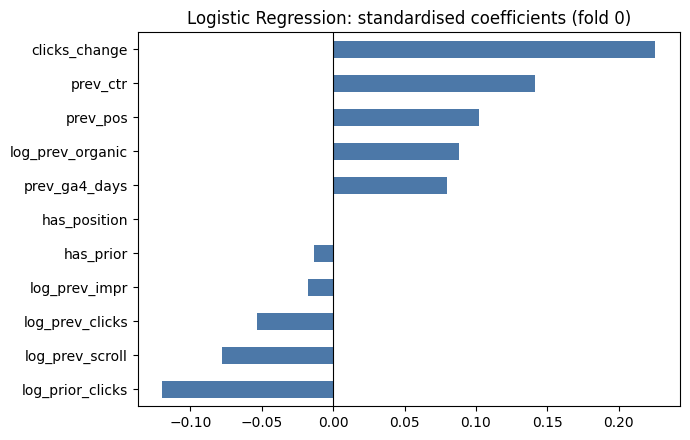

In [13]:
# Logistic regression coefficients (standardised, so sizes are comparable)
lr_make, lr_prep = SPECS["Logistic Regression"]
lr = lr_make().fit(lr_prep(frame.iloc[tr0]), frame.iloc[tr0]["y"])
coefs = pd.Series(lr[-1].coef_[0], index=lr_prep(frame.iloc[tr0]).columns).sort_values()
ax = coefs.plot.barh(figsize=(7, 4.5), color="#4C78A8")
ax.set_title("Logistic Regression: standardised coefficients (fold 0)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout(); plt.show()

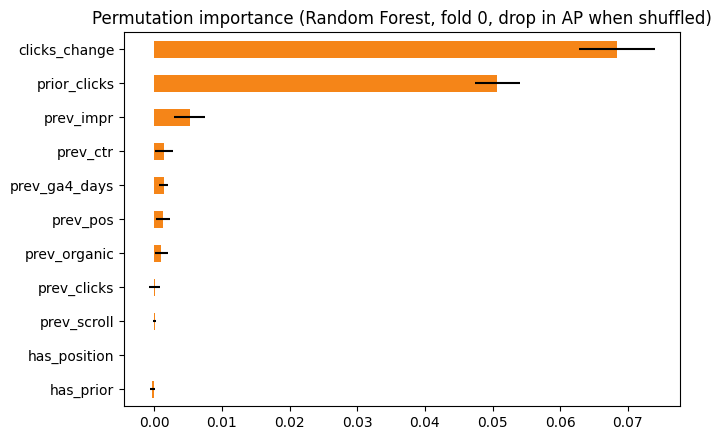

Top 3 features: ['clicks_change', 'prior_clicks', 'prev_impr']


In [14]:
# Permutation importance for the best learned model, on held-out clients (fold 0)
from sklearn.inspection import permutation_importance

make, prep = SPECS[best_name]
tr_fit0 = frame.iloc[tr0] if len(tr0) <= TRAIN_CAP else frame.iloc[tr0].sample(TRAIN_CAP, random_state=SEED)
Xtr0, Xte_full = prep(tr_fit0), prep(frame.iloc[te0])
if best_name == "Random Forest":
    Xtr0, Xte_full = RF_FILL(Xtr0), RF_FILL(Xte_full)
model0 = make().fit(Xtr0, tr_fit0["y"])

test_sample = frame.iloc[te0].sample(min(30_000, len(te0)), random_state=SEED)
Xte_s = prep(test_sample)
if best_name == "Random Forest":
    Xte_s = RF_FILL(Xte_s)

pi = permutation_importance(model0, Xte_s, test_sample["y"], scoring="average_precision",
                            n_repeats=5, random_state=SEED, n_jobs=-1)
pi_df = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std},
                     index=Xte_s.columns).sort_values("importance")
ax = pi_df["importance"].plot.barh(xerr=pi_df["std"], figsize=(7, 4.5), color="#F58518")
ax.set_title(f"Permutation importance ({best_name}, fold 0, drop in AP when shuffled)")
plt.tight_layout(); plt.show()
print("Top 3 features:", list(pi_df.index[::-1][:3]))

In [15]:
# Where does the best model go wrong? Look at its top-500 picks in every fold.
picks = []
for i in range(N_FOLDS):
    part = oof[oof["fold"] == i]
    top = part.sort_values(best_name, ascending=False).head(K_LARGE)
    picks.append(top.index)
picks_idx = np.concatenate(picks)

view = frame.copy()
view["picked"] = False
view.loc[picks_idx, "picked"] = True
view["score"] = oof[best_name]

# 1) by size of the page (previous-week clicks)
view["size_band"] = pd.qcut(view["prev_clicks"], 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"])
all_pages = view.groupby("size_band", observed=True)
chosen = view[view["picked"]].groupby("size_band", observed=True)
by_size = pd.DataFrame({
    "share_of_all_pages": all_pages.size() / len(view),
    "share_of_top_picks": chosen.size() / view["picked"].sum(),
    "drop_rate_all_pages": all_pages["y"].mean(),
    "drop_rate_in_picks": chosen["y"].mean(),
})
print("By page size (previous-week clicks)")
display(by_size.round(3))

# 2) by decision week
by_week = view.groupby("decision_date").agg(drop_rate_all_pages=("y", "mean"))
by_week["picks"] = view[view["picked"]].groupby("decision_date").size()
by_week["drop_rate_in_picks"] = view[view["picked"]].groupby("decision_date")["y"].mean()
print("By decision week")
display(by_week.round(3))

By page size (previous-week clicks)


,share_of_all_pages,share_of_top_picks,drop_rate_all_pages,drop_rate_in_picks
size_band,,,,
smallest 25%,0.260,0.513,0.385,0.452
25-50%,0.256,0.312,0.438,0.621
50-75%,0.248,0.157,0.411,0.579
largest 25%,0.236,0.018,0.301,0.523


By decision week


,drop_rate_all_pages,picks,drop_rate_in_picks
decision_date,,,
2026-03-08,0.417,540,0.609
2026-03-15,0.422,500,0.668
2026-03-22,0.340,511,0.519
2026-03-29,0.370,949,0.408


In [16]:
# 3) client by client (relabelled C1, C2, ... so no ids are shown)
rows = []
for cid, g in view.groupby("client_hash_id"):
    if len(g) >= 300 and 0 < g["y"].sum() < len(g):
        rows.append({"client": cid, "rows": len(g), "base_rate": g["y"].mean(),
                     "AP": average_precision_score(g["y"], g["score"])})
by_client = pd.DataFrame(rows).sort_values("rows", ascending=False).reset_index(drop=True)
by_client["client"] = [f"C{i+1}" for i in range(len(by_client))]
by_client["AP_minus_base_rate"] = by_client["AP"] - by_client["base_rate"]
print(f"{best_name}: average precision per client (clients with at least 300 rows)")
display(by_client.round(3))

Random Forest: average precision per client (clients with at least 300 rows)


,client,rows,base_rate,AP,AP_minus_base_rate
0,C1,4912,0.363,0.559,0.196
1,C2,2876,0.453,0.560,0.108
2,C3,2648,0.420,0.597,0.177
3,C4,1510,0.391,0.506,0.115
4,C5,1226,0.117,0.129,0.012
5,C6,970,0.413,0.591,0.178
6,C7,865,0.439,0.566,0.127
7,C8,724,0.362,0.466,0.105


In [17]:
# Single cases. Three most confident false alarms and three biggest misses of the best model.
show = ["decision_date", "prev_clicks", "prior_clicks", "future_clicks", "prev_ctr", "prev_pos", "score"]
test_view = view.copy()

false_alarms = test_view[(test_view["picked"]) & (test_view["y"] == 0)].sort_values("score", ascending=False).head(3)
print("Confident false alarms (model said 'will drop', clicks did not fall enough)")
display(false_alarms[show].round(3))

misses = test_view[(test_view["y"] == 1)].copy()
misses["clicks_lost"] = misses["prev_clicks"] - misses["future_clicks"]
misses = misses.sort_values("clicks_lost", ascending=False).head(3)
print("Biggest misses (page lost the most clicks, model scored it low)")
display(misses[show + ["clicks_lost"]].round(3))

Confident false alarms (model said 'will drop', clicks did not fall enough)


,decision_date,prev_clicks,prior_clicks,future_clicks,prev_ctr,prev_pos,score
27,2026-03-08,11.0,2.0,12.0,0.013,3.849,0.800
11557,2026-03-29,11.0,1.0,14.0,0.018,5.946,0.778
3777,2026-03-15,11.0,0.0,22.0,0.020,6.266,0.775


Biggest misses (page lost the most clicks, model scored it low)


,decision_date,prev_clicks,prior_clicks,future_clicks,prev_ctr,prev_pos,score,clicks_lost
13225,2026-03-29,488.0,111.0,36.0,0.007,12.005,0.352,452.0
10848,2026-03-22,318.0,NaN,25.0,0.009,3.202,0.408,293.0
12378,2026-03-29,704.0,639.0,453.0,0.013,4.515,0.195,251.0


In [18]:
# Plain-language summary computed from the numbers above, so the text cannot drift from the table
g = fold_results.groupby("model")
mean_ = g[["P@50", "P@500", "AP", "ROC-AUC"]].mean()
std_ = g[["P@50", "P@500", "AP", "ROC-AUC"]].std()

print(f"Base rate of a meaningful drop: {base_rate:.1%}")
print(f"Week 4 baseline:  P@50 {mean_.loc['Week 4 baseline','P@50']:.3f} | P@500 {mean_.loc['Week 4 baseline','P@500']:.3f} | AP {mean_.loc['Week 4 baseline','AP']:.3f}")
print(f"{best_name} (best by AP): P@50 {mean_.loc[best_name,'P@50']:.3f} | P@500 {mean_.loc[best_name,'P@500']:.3f} | AP {mean_.loc[best_name,'AP']:.3f}")

# Is the extra complexity earning its keep? Compare with the simplest learned model, Logistic Regression.
lr_ap, lr_sd = mean_.loc["Logistic Regression", "AP"], std_.loc["Logistic Regression", "AP"]
best_ap = mean_.loc[best_name, "AP"]
if best_name == "Logistic Regression":
    print("The simplest model is also the best one.")
elif best_ap - lr_ap <= lr_sd:
    print(f"{best_name} beats Logistic Regression by {best_ap-lr_ap:.3f} AP, which is within one fold-to-fold std ({lr_sd:.3f}). The extra complexity is not clearly earning anything.")
else:
    print(f"{best_name} beats Logistic Regression by {best_ap-lr_ap:.3f} AP, more than one fold-to-fold std ({lr_sd:.3f}).")

Base rate of a meaningful drop: 38.5%
Week 4 baseline:  P@50 0.344 | P@500 0.372 | AP 0.367
Random Forest (best by AP): P@50 0.692 | P@500 0.526 | AP 0.504
Random Forest beats Logistic Regression by 0.002 AP, which is within one fold-to-fold std (0.118). The extra complexity is not clearly earning anything.


### My reading of the results

_To be written from the numbers above after the notebook has been run._

### Final model vs baseline table

In [19]:
comparison

,P@50,P@500,AP,ROC-AUC
Random list (base rate),0.385,0.385,0.385,0.500
Week 4 baseline,0.344 ± 0.071,0.372 ± 0.040,0.367 ± 0.064,0.440 ± 0.033
Logistic Regression,0.664 ± 0.134,0.549 ± 0.146,0.502 ± 0.118,0.611 ± 0.094
Decision Tree (depth 3),0.636 ± 0.111,0.504 ± 0.211,0.444 ± 0.111,0.555 ± 0.090
Random Forest,0.692 ± 0.106,0.526 ± 0.222,0.504 ± 0.138,0.609 ± 0.112
Gradient Boosting,0.696 ± 0.071,0.505 ± 0.238,0.495 ± 0.143,0.602 ± 0.114


## Limits to keep in mind

- The label is "clicks fell by at least 30% week over week", which is an observed pattern. It does not say *why* a page dropped, and it does not say a refresh would bring clicks back.
- Pages that drop after a very good week tend to bounce back on their own (regression to the mean), so some "drops" are just noise. Requiring at least 10 clicks in the previous week reduces this but does not remove it.
- Only four weekly decision dates in March 2026 are used, all from one warehouse release. Results are directional and should not be read as a general rule.

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.